In [233]:
import os
import unittest

import librosa
import numpy as np

import brucezilany

from scipy.signal import savgol_filter, find_peaks
import matplotlib.pyplot as plt

def delay(cf):
    a0 = 3.0
    a1 = 12.5
    x = 11.9 * np.log10(0.80 + (cf / 456.0)) 
    return a0 * np.exp(-x / a1) * 1e-3

def get_whitenoise(sampling_rate, duration):
    n_timesteps = int(np.ceil(duration * sampling_rate))
    data = np.random.normal(0, 1, n_timesteps)
    return brucezilany.stimulus.Stimulus(data, sampling_rate, duration)


def get_peak_period(data, dt, height=5, **kwargs):
    data_sm = savgol_filter(data, 5, 1)
    peaks, *_ = find_peaks(data_sm, height=height, **kwargs)
    return  (np.median(np.diff(peaks)) * dt)

def get_peak_phase(data, dt, **kwargs):
    return 1 / get_peak_period(data, dt)

In [234]:
brucezilany.set_seed(31)

stim = get_whitenoise(100000, 0.05)
stim = brucezilany.stimulus.normalize_db(stim, 65.0)

n_trials = 20
n_fibers = 10

n_low_med = int(np.floor(n_fibers / 5))
n_high = n_fibers - (2 * n_low_med)

min_freq = 150
max_freq = 2500
n_bins = 1
n_mels = int(2500 / 10_500 * 64) 

mel_scale = librosa.filters.mel_frequencies(n_mels, fmin=min_freq, fmax=max_freq)

ng = brucezilany.Neurogram(
    mel_scale,
    n_low=n_low_med,
    n_med=n_low_med,
    n_high=n_high,
    n_threads=10
)
ng.bin_width = 1 / (max_freq * 2 * n_bins)

ng.create(stim, n_rep=1, n_trials=n_trials)

data = ng.get_output().sum(axis=1)

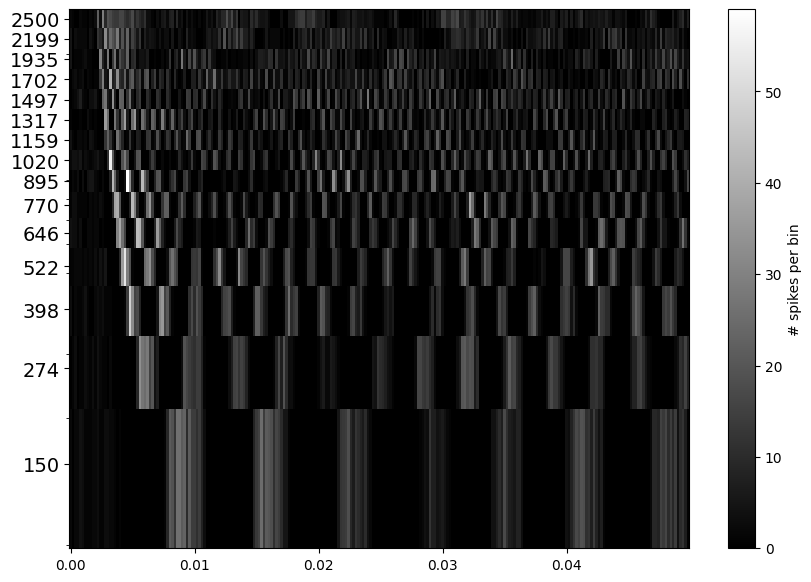

In [235]:
plt.figure(figsize=(10, 7))
t = np.arange(data.shape[1]) * ng.bin_width
plt.pcolormesh(t, mel_scale, data, cmap='gray')
plt.colorbar(label='# spikes per bin')
plt.yscale("log", base=10)
plt.yticks(mel_scale.astype(int), mel_scale.astype(int), fontsize=14);

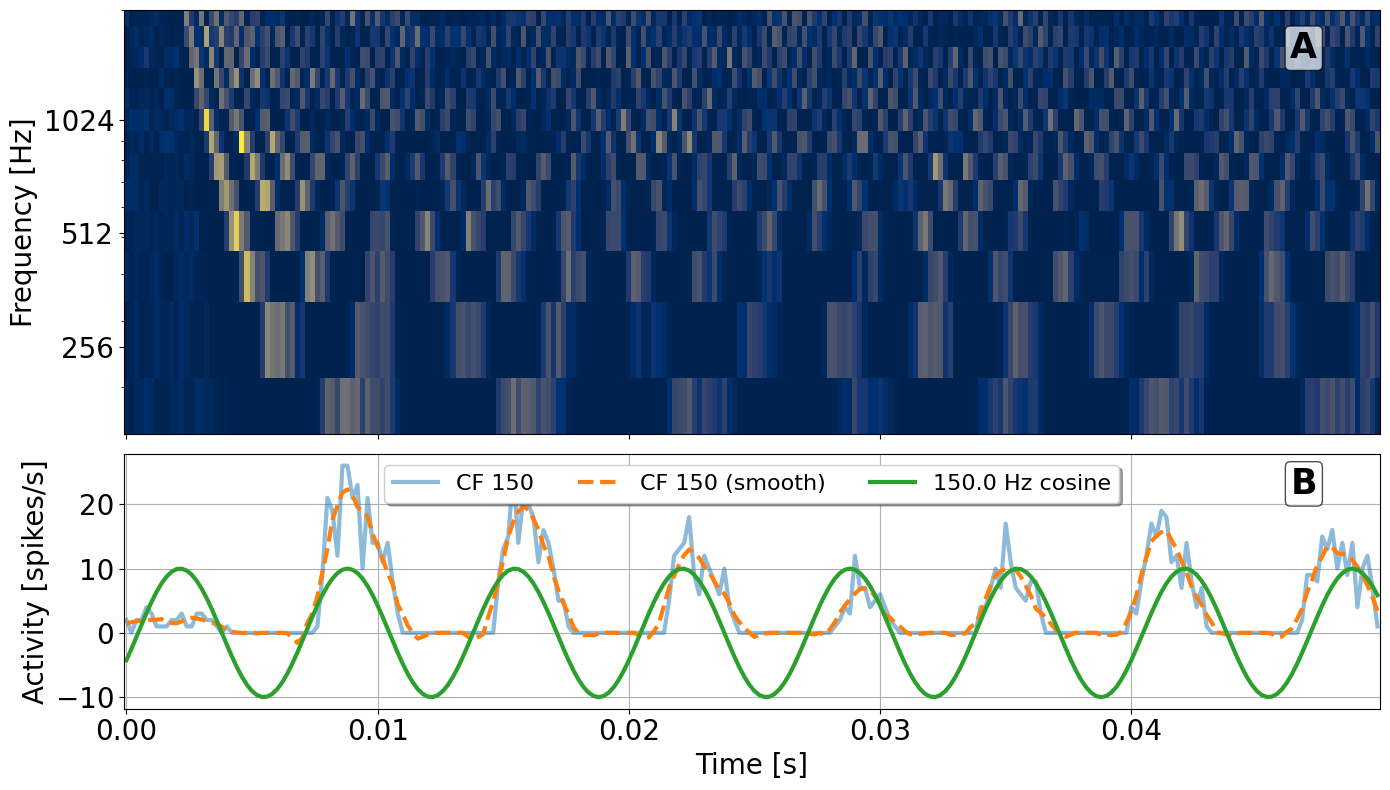

In [333]:
idx = 0

data_sm = savgol_filter(data[idx], 13, 2)
peaks, *_ = find_peaks(data_sm, height=5)
delay_ = ng.bin_width * peaks[0]

f, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), height_ratios=[5, 3], sharex=True)

ax1.pcolormesh(t, mel_scale, data, cmap='cividis')
ax1.set_yscale("log")
ax1.set_ylabel("Frequency [Hz]",  fontsize=20)
ax1.set_yticks([pow(2, i) for i in range(8, 14)], [pow(2, i) for i in range(8, 14)], fontsize=14)
ax1.set_ylim(min_freq, 2000)
ax1.tick_params(axis='both', which='major', labelsize=20)

ax2.plot(t, data[idx], label='CF 150', alpha=.5, linewidth=3)
ax2.plot(t, data_sm, label='CF 150 (smooth)', linestyle='dashed', linewidth=3)
ax2.plot(
    t, 
    10 * np.cos(2 * np.pi * (mel_scale[idx])  * (t - delay_)), 
    # label=f'Cosine wave ({mel_scale[idx]:.0f} Hz)',
    label=f"{mel_scale[idx]:.1f} Hz cosine",
    linewidth=3
)

ax2.tick_params(axis='both', which='major', labelsize=20)

ax2.set_ylabel("Activity [spikes/s]", fontsize=20)
ax2.set_xlabel("Time [s]", fontsize=20)

# plt.scatter(t[peaks], data_sm[peaks], color='red', zorder=100, label=f'peaks (period: {get_peak_period(data_sm, ng.bin_width, 5):.4f})')


# period = 1 / mel_scale[idx]
# expected_peaks = np.arange(delay_, max(t) + ng.bin_width, period)
# plt.scatter(expected_peaks, np.ones(expected_peaks.size) * 4, label=f'expected peaks (period: {period:.4f})')

ax2.grid()
ax2.legend(fontsize=16, loc='upper center', ncol=3, fancybox=True, shadow=True)

for ax, label in zip((ax1, ax2), "AB"):
    ax.text(0.95, 0.95, label,
        transform=ax.transAxes,
        fontsize=25, fontweight='bold',
        va='top', ha='right',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='black', boxstyle='round,pad=0.15'))
    
plt.tight_layout()
plt.savefig("noise_activity.png", dpi=500)

In [326]:
delay_, delay(150)

(np.float64(0.0088), np.float64(0.0028532734967128817))

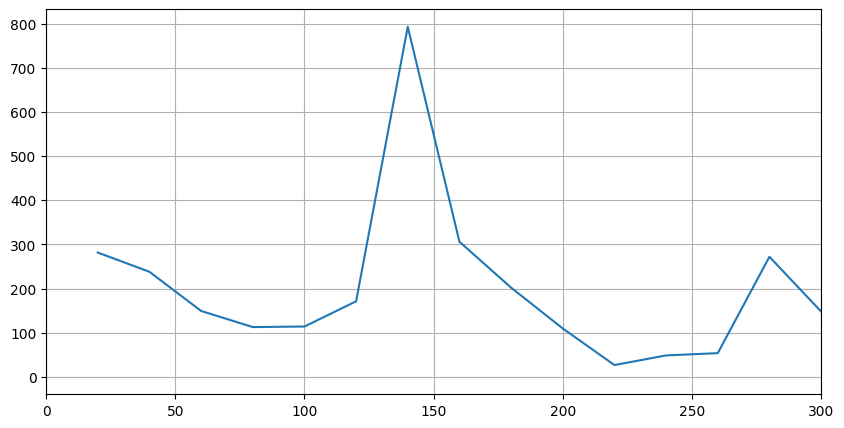

In [202]:
spectrum = np.abs(np.fft.fft(data_sm))
plt.figure(figsize=(10, 5))
plt.plot(np.fft.fftfreq(len(data_sm), ng.bin_width)[1:len(spectrum) // 2], spectrum[1:len(spectrum) // 2])
plt.xlim(0, 300)
plt.grid()

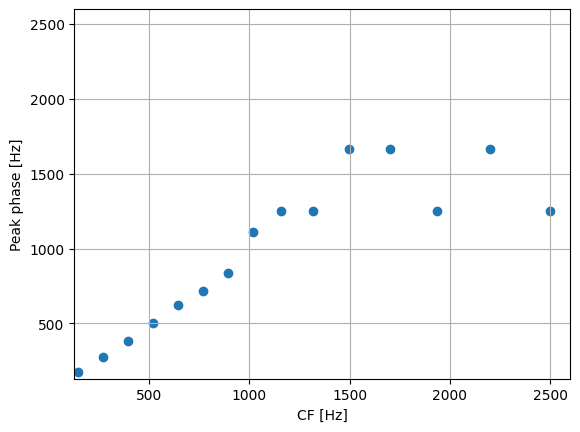

In [122]:
phases = np.array([get_peak_phase(d, ng.bin_width) for d in data])
plt.scatter(mel_scale, phases)
plt.xlabel("CF [Hz]")
plt.ylabel("Peak phase [Hz]")
plt.xlim(130, 2600)
plt.ylim(130, 2600)
plt.grid()

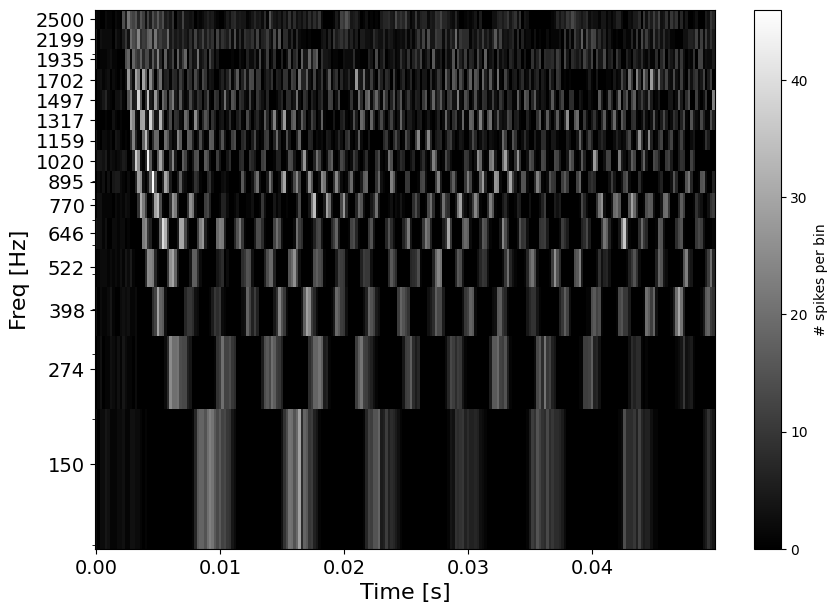

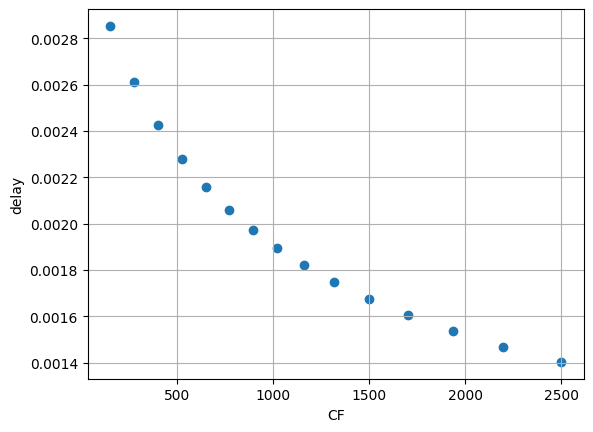

In [123]:
plt.figure(figsize=(10, 7))
plt.pcolormesh(np.arange(data.shape[1]) * ng.bin_width, mel_scale, data, cmap='gray')
plt.colorbar(label='# spikes per bin')
plt.yscale("log", base=10)
plt.yticks(mel_scale.astype(int), mel_scale.astype(int), fontsize=14)

plt.xticks(fontsize=14)
plt.ylabel("Freq [Hz]", fontsize=16)
plt.xlabel("Time [s]", fontsize=16)


plt.figure()
plt.scatter(mel_scale, delay(mel_scale))
plt.xlabel("CF")
plt.ylabel("delay")
plt.grid()

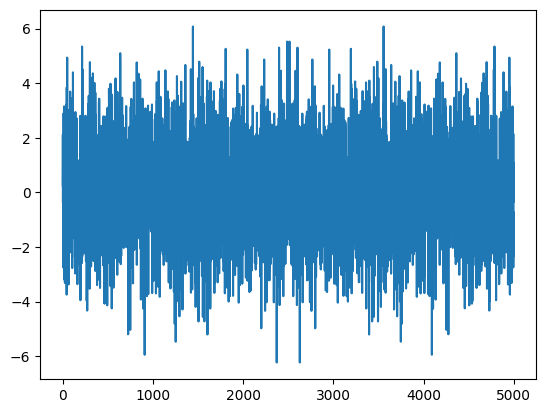

In [ ]:
np.fft.fftfreq(data_sm.size, ng.bin_width)

(15, 79)


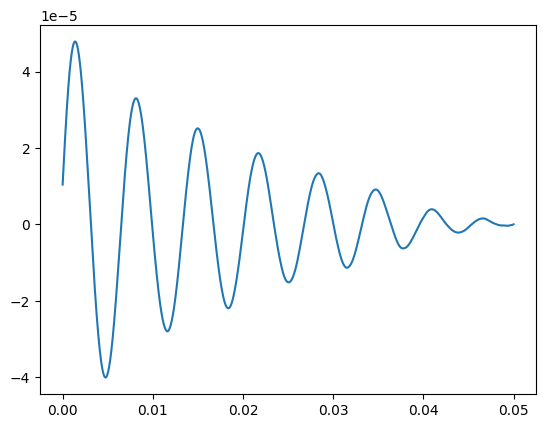

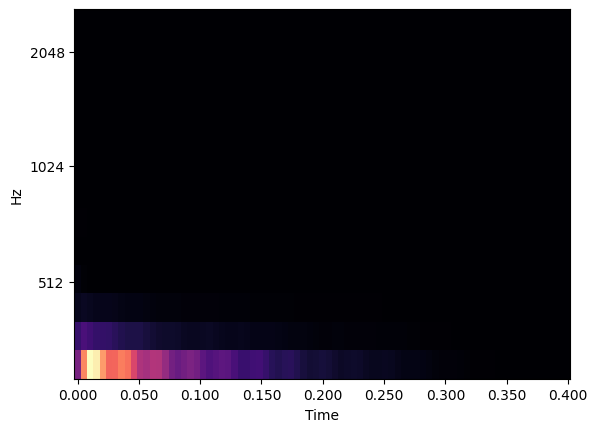

In [102]:
fmax = 2500
fmin = 150
n_fft = 512

from scipy.signal import butter, filtfilt

def bandpass_filter(data, lowcut=149, highcut=151, fs=1000, order=1):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

y = stim.data.copy()
y = bandpass_filter(y, fs=stim.sampling_rate)
plt.plot(np.arange(len(y))*1/stim.sampling_rate, y)
# plt.plot(stim.data)
plt.figure()

S = librosa.feature.melspectrogram(y=y, sr=stim.sampling_rate, fmax=fmax, fmin=fmin, n_mels=n_mels, n_fft=n_fft, hop_length=n_fft // 8)
freq = librosa.mel_frequencies(fmax=fmax, fmin=fmin)

print(S.shape)
librosa.display.specshow(
    S, 
    sr=stim.sampling_rate,
    x_axis='time',
    y_axis='mel',
    fmax=fmax,
    fmin=fmin
)

1250.0